# 01 · The Problem and the Data
**Course Module 1: Understanding the Vision Problem** (task identification, specifics identification)

**What you will learn in this notebook**
1. The real-world problem, and why it is an *image classification* task
2. The two datasets: PlantVillage (lab photos) and PlantDoc (field photos)
3. How to split data honestly (the "same leaf" leakage trap)
4. Proof that lab photos contain a **shortcut** a model can cheat with

---
## 0. The project strategy in one table

| Step | Notebook | Course module | Strategy: what we do and why |
|---|---|---|---|
| Understand | **01** (this one) | M1 Vision problem | Define the task, audit the data, find what makes it hard *before* training anything |
| Baseline | 02 | M2 Classification, M3 Model design | Build a CNN from scratch, follow every tensor shape and parameter, measure the lab-to-field gap |
| Reuse knowledge | 03 | M2 Transfer learning, M3 Architectures | Pretrained backbones: linear probe vs fine-tuning; compare architectures on *field* accuracy, size and speed |
| Fix the data | 04 | M4 Data augmentation | Controlled ablation: add one augmentation at a time and measure field accuracy |
| Train better | 05 | M5 Optimization, loss, metrics, activations | Optimizers, losses, activations; metrics beyond accuracy; calibration and "I'm not sure" |
| Explain and ship | 06 + app | (Streamlit, preview of M7) | Grad-CAM shows what the model looks at; export to ONNX; Streamlit demo |

**The one rule behind every decision:** the PlantDoc *test* set is the final exam. It is never used for training or for picking settings, so every field number is honest.

---
## 1. The problem, in simple words

A farmer sees spots on a leaf. Which disease is it, and what should they spray?

- In India there is roughly **1 government extension worker for every ~1,160 farm holdings** (ICRIER 2018, using 2012-13 data). In Punjab, over 40% of Agricultural Development Officer posts were vacant in Oct 2026 (The Tribune).
- A wrong guess means the wrong pesticide: money lost, crop lost, chemicals wasted.
- Rural internet is patchy: 48 rural internet subscriptions per 100 people vs 127 in cities (TRAI, March 2026).

So the goal is a **phone app that diagnoses a leaf photo, works offline, and says "I'm not sure" when it should**.

## 2. Why this is an *image classification* task

| Question (Module 1 checklist) | Answer for this project |
|---|---|
| What is the input? | One photo of a leaf |
| What is the output? | One label: crop + disease (e.g. "Tomato late blight") |
| Do we need *where* the disease is (detection) or the exact pixels (segmentation)? | Not to give advice. One label per photo is enough → **classification** |
| Where will it run? | On a phone, offline → the model must be small and fast |
| What makes it hard? | Field photos look nothing like the training photos (next section) |

## 3. The hidden problem: "lab to field"

Most research uses **PlantVillage**: 54,306 photos of single leaves on a plain board, taken in a lab. Models score ~99% on it.
But on real field photos, published models collapse:

| Paper | Lab accuracy | Field accuracy |
|---|---|---|
| Mohanty et al. 2016 (GoogLeNet) | 99.35% | 31.4% on web images |
| Singh et al. 2020, PlantDoc (InceptionResNetV2) | high | 39.9% |
| Xiang et al. 2026 (ResNet-50) | 99.73% | 32.05%, while still ~80% confident |

**Our project's question:** how much of this gap can we close, and can the model at least *know* when it is unsure?

In [1]:
# Setup: our own small library lives in src/lab_to_field (shared by every notebook)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from lab_to_field.config import CLASSES, CLASS_MAP, N_CLASSES, FIGURES_DIR
from lab_to_field.data import load_plantvillage, load_plantdoc, cache_plantdoc, split_by_group, drop_shared_leaves
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
print("number of shared classes:", N_CLASSES)

number of shared classes: 28


## 4. The datasets

| | PlantVillage (lab) | PlantDoc (field) |
|---|---|---|
| Photos | 54,306 (38 classes) | 2,598 (28 classes) |
| How taken | One leaf, plain background, lab lighting | Real scenes from the web: many leaves, soil, hands, sky |
| License | CC BY-SA 3.0 | CC BY 4.0 |
| Our use | **Training** | **Field test** (and optional extra training in the "field" track) |

We keep only the **28 classes that exist in both** (`config.CLASS_MAP`), because a class that the field test does not contain cannot be scored.

**Practical choices (and why):**
- **PlantVillage subset.** `scripts/download_plantvillage_subset.py` downloads up to ~700 train and ~150 test photos per class, chosen **by whole leaf** (36 k files, 480 MB instead of the 2.2 GB zip). More photos of the same leaves add little new information, and the leaf-safe split is kept.
- **PlantDoc resized once** to 256 px (originals are several megapixels), which makes training much faster.

In [2]:
cache_plantdoc(256)     # one-time resize; skips files that already exist
pv_train, pv_test = load_plantvillage("train"), load_plantvillage("test")
pd_train, pd_test = load_plantdoc("train"), load_plantdoc("test")
counts = pd.DataFrame({
    "PV train": pv_train.label.value_counts().sort_index(),
    "PV test": pv_test.label.value_counts().sort_index(),
    "PlantDoc train": pd_train.label.value_counts().sort_index(),
    "PlantDoc test": pd_test.label.value_counts().sort_index(),
}).fillna(0).astype(int)
counts.index = [CLASSES[i] for i in counts.index]
print({k: len(v) for k, v in dict(pv_train=pv_train, pv_test=pv_test, pd_train=pd_train, pd_test=pd_test).items()})
counts

{'pv_train': 16664, 'pv_test': 3781, 'pd_train': 2327, 'pd_test': 236}


,PV train,PV test,PlantDoc train,PlantDoc test
Apple scab,503,127,83,10
Apple healthy,704,155,82,9
Apple cedar rust,223,52,79,10
Bell pepper spot,703,156,62,9
Bell pepper healthy,707,163,53,8
Blueberry healthy,700,153,105,11
Cherry healthy,706,123,47,10
Corn gray leaf spot,406,107,62,4
Corn leaf blight,700,150,179,12
Corn rust,700,150,106,10


**Read the table:** PlantDoc is small and **imbalanced** (some classes have 3× more photos than others), and the full PlantVillage is too (5,357 tomato-yellow-leaf-curl photos vs 371 raspberry). We cap lab training at 500 photos per class and report macro-F1, which weighs every class equally (notebook 05).
PlantDoc test has only ~230 photos, so every field number we report also gets a **95% confidence interval**.

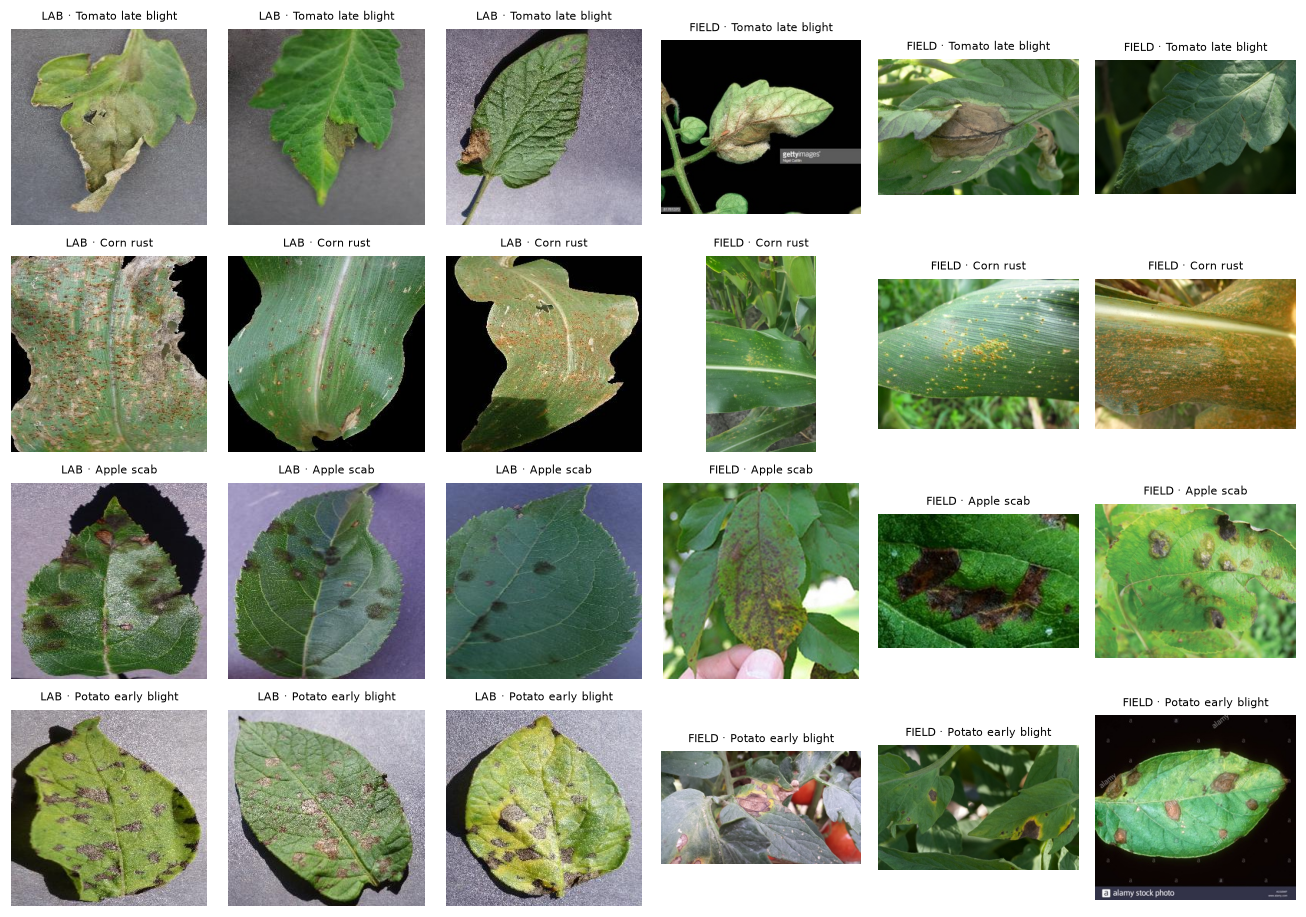

In [3]:
# Look at the data: same disease, lab vs field
def show_pairs(class_names, n=3):
    fig, axes = plt.subplots(len(class_names), 2 * n, figsize=(2 * 2 * n, 2.1 * len(class_names)))
    for r, name in enumerate(class_names):
        idx = CLASSES.index(name)
        lab = pv_train[pv_train.label == idx].sample(n, random_state=1).path
        field = pd_train[pd_train.label == idx].sample(n, random_state=1).path
        for c, p in enumerate(list(lab) + list(field)):
            ax = axes[r, c]; ax.imshow(Image.open(p).convert("RGB")); ax.axis("off")
            ax.set_title(("LAB · " if c < n else "FIELD · ") + name, fontsize=7)
    plt.tight_layout(); return fig

fig = show_pairs(["Tomato late blight", "Corn rust", "Apple scab", "Potato early blight"])
fig.savefig(FIGURES_DIR / "01_lab_vs_field.png", bbox_inches="tight")

**What you see:** lab photos are one centered leaf on a uniform board. Field photos have several leaves, shadows, soil, blur and different scales.
A model trained only on the left half has never seen anything like the right half. This is called **domain shift**.

## 5. Honest splitting: the "same leaf" trap

PlantVillage often has **several photos of the same physical leaf**. If one photo of a leaf is in training and another photo of the same leaf is in the test set, the model can "remember" the leaf, and the test score is inflated. This is called **data leakage**.

The dataset authors published a `leaf_id` for each photo. We split by `leaf_id` (scikit-learn `GroupShuffleSplit`), so each leaf is in exactly one split.

In [4]:
photos_per_leaf = pv_train.groupby("leaf_id").size()
print(f"{len(pv_train):,} photos come from {photos_per_leaf.size:,} distinct leaves")
print("photos per leaf:", photos_per_leaf.describe()[["mean", "max"]].round(2).to_dict())

shared = set(pv_train.leaf_id) & set(pv_test.leaf_id)
print(f"leaves in BOTH the official train and test split: {len(shared)}")
clean_train = drop_shared_leaves(pv_train, pv_test)
print(f"removed {len(pv_train) - len(clean_train)} training photos of those leaves")

tr, va = split_by_group(clean_train, 0.1)
print("leaves shared by our train and validation splits:", len(set(tr.leaf_id) & set(va.leaf_id)))
print("leaves shared by our training data and the test set:", len(set(clean_train.leaf_id) & set(pv_test.leaf_id)))

16,664 photos come from 6,751 distinct leaves
photos per leaf: {'mean': 2.47, 'max': 20.0}
leaves in BOTH the official train and test split: 37
removed 53 training photos of those leaves
leaves shared by our train and validation splits: 0
leaves shared by our training data and the test set: 0


PlantDoc train photos that duplicate a test photo: 15 (removed from training)


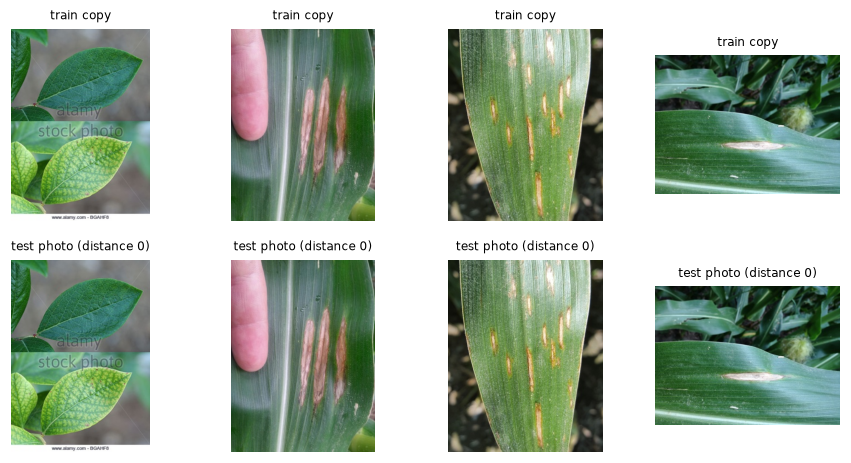

In [5]:
from lab_to_field.data import find_plantdoc_duplicates
dupes = find_plantdoc_duplicates()
print(f"PlantDoc train photos that duplicate a test photo: {len(dupes)} (removed from training)")
if dupes:
    import imagehash
    test_hashes = {p: imagehash.phash(Image.open(p)) for p in pd_test.path}
    fig, axes = plt.subplots(2, min(4, len(dupes)), figsize=(10, 5), squeeze=False)
    for c, d in enumerate(dupes[:4]):
        h = imagehash.phash(Image.open(d)); t = min(test_hashes, key=lambda p: test_hashes[p] - h)
        axes[0, c].imshow(Image.open(d)); axes[0, c].set_title("train copy", fontsize=8)
        axes[1, c].imshow(Image.open(t)); axes[1, c].set_title(f"test photo (distance {test_hashes[t] - h})", fontsize=8)
    for a in axes.ravel(): a.axis("off")
    fig.savefig(FIGURES_DIR / "01_duplicates.png", bbox_inches="tight")

**Result:** even the *official* split has a few leaves on both sides (printed above). We remove those photos from training, so our train, validation and test sets share **zero** leaves.
Lesson: never trust a split blindly; check it.

### The same trap in PlantDoc: duplicate web images
PlantDoc was collected by web search, so the *same picture* can appear in both its train and test folders (re-sized or re-compressed).
We compare **perceptual hashes** (pHash): a 64-bit fingerprint of the image's overall structure that survives resizing and JPEG compression. Two images whose hashes differ in ≤ 4 bits are treated as the same photo, and that train copy is dropped.

## 6. The shortcut: can a model guess the disease from the *background*?

If photos of each disease were taken on slightly different days, boards or lighting, the background itself carries label information.
Test: throw away the leaf entirely and keep **only the 4 corner patches** (4 × 8×8 pixels, mostly background). Train a simple classifier on those corners.

- Chance level with 28 classes = 1/28 = **3.6%**
- If corners alone score far above chance, a CNN can also learn this shortcut instead of learning disease symptoms.

In [6]:
from sklearn.ensemble import RandomForestClassifier

def corner_features(path, k=8):
    a = np.asarray(Image.open(path).convert("RGB").resize((256, 256)), dtype=np.float32)
    corners = [a[:k, :k], a[:k, -k:], a[-k:, :k], a[-k:, -k:]]
    return np.concatenate([[c.mean((0, 1)), c.std((0, 1))] for c in corners]).ravel()

from lab_to_field.data import cap_per_class
tr_s, te_s, pd_s = cap_per_class(pv_train, 150), cap_per_class(pv_test, 60), pd_test
Xtr = np.stack([corner_features(p) for p in tr_s.path]); Xte = np.stack([corner_features(p) for p in te_s.path])
Xpd = np.stack([corner_features(p) for p in pd_s.path])
rf = RandomForestClassifier(300, n_jobs=-1, random_state=0).fit(Xtr, tr_s.label)
print(f"chance level                         : {1 / N_CLASSES:.1%}")
print(f"corners only, PlantVillage test       : {rf.score(Xte, te_s.label):.1%}")
print(f"corners only, PlantDoc (field) test   : {rf.score(Xpd, pd_s.label):.1%}")

chance level                         : 3.6%
corners only, PlantVillage test       : 46.1%
corners only, PlantDoc (field) test   : 5.9%


**What this means:** the background corners of lab photos predict the disease far better than chance, without looking at a single leaf pixel. In field photos this shortcut disappears.
This explains part of the lab-to-field collapse: lab accuracy rewards shortcuts. In notebook 04 we attack this directly with **background replacement**.

(Noyan 2022 reported the same effect: 49% accuracy from only 8 background pixels of PlantVillage.)

## 7. Image statistics: how different are the two worlds?

,brightness,saturation,edge density
domain,,,
field,0.625,0.392,13.617
lab,0.512,0.255,20.959


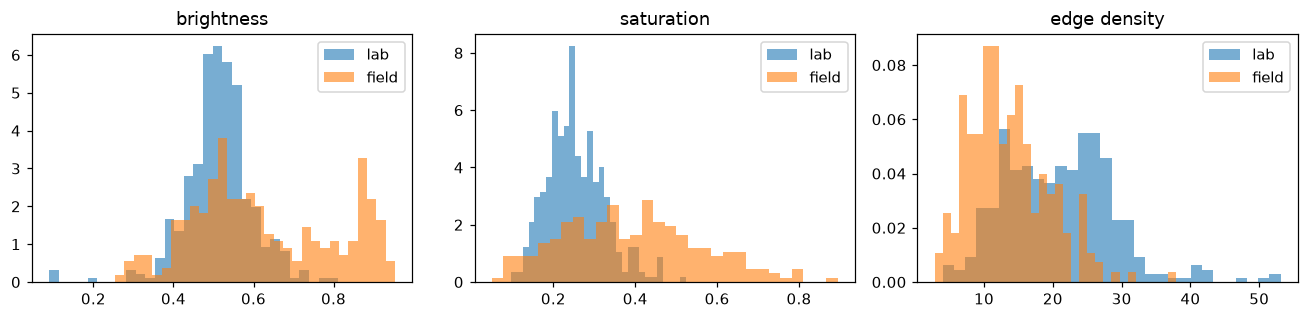

In [7]:
def stats(path):
    im = Image.open(path).convert("RGB").resize((224, 224))
    hsv = np.asarray(im.convert("HSV"), dtype=np.float32) / 255
    g = np.asarray(im.convert("L"), dtype=np.float32)
    edges = np.abs(np.diff(g, axis=0)).mean() + np.abs(np.diff(g, axis=1)).mean()
    return hsv[..., 2].mean(), hsv[..., 1].mean(), edges

rows = [("lab", *stats(p)) for p in pv_test.sample(400, random_state=0).path] + \
       [("field", *stats(p)) for p in pd_test.path]
st = pd.DataFrame(rows, columns=["domain", "brightness", "saturation", "edge density"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, st.columns[1:]):
    for dom, c in [("lab", "tab:blue"), ("field", "tab:orange")]:
        ax.hist(st[st.domain == dom][col], bins=30, alpha=.6, density=True, label=dom, color=c)
    ax.set_title(col); ax.legend()
plt.tight_layout(); fig.savefig(FIGURES_DIR / "01_image_stats.png", bbox_inches="tight")
st.groupby("domain").mean().round(3)

**What this means:** field photos are brighter and more saturated (sunlight), and have *less* fine edge detail (web photos are softer, more compressed and often slightly out of focus), while lab photos are sharp close-ups.
The model must handle different lighting, color and sharpness. That is exactly what the `color` augmentation in notebook 04 imitates (brightness/saturation jitter and blur).

---
## Summary

| Finding | Consequence for the project |
|---|---|
| The task is single-label classification of a leaf photo | Classification models, Modules 2-5 |
| 28 classes shared between lab and field data | We train and test on these 28 |
| Same-leaf photos exist, even across the official split | We split by `leaf_id` and drop shared leaves → no leakage |
| PlantDoc has train/test duplicates | Removed with perceptual hashing |
| Backgrounds leak the label in lab photos | Lab accuracy is inflated; we must test in the field |
| Field photos differ in brightness, color and sharpness | Augmentation must imitate these |

## Review questions
1. Why is this classification and not detection or segmentation?
2. What is domain shift? Give an example from this notebook.
3. What is data leakage? Name the two leaks we found and how we prevented each.
4. Why is 99% on PlantVillage not a convincing result?
5. What is the chance accuracy for 28 classes, and why do we compare against it?